# EMQA_L3_vol_units

**Standard deviation of the daily shocks of the Romanian base price by year, 2019-01-01 to 2026-10-31, in percent (left) and in EUR/MWh (right)**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_vol_units/EMQA_L3_vol_units.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

## Volatility in two units

Shocks = residuals of the mean equation (constant + AR(1..7) + day-of-week dummies) for the percent change $r_t$ ($\varepsilon_t$) and for the change in EUR/MWh $\Delta P_t$ ($u_t$). Yearly standard deviations.

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# daily changes on the full calendar: percent (log) and EUR/MWh
r = 100 * np.log(P.where(P > 0)).diff()      # r_t = 100 ln(P_t / P_{t-1}); missing if a price is <= 0
u = P.diff()                                  # Delta P_t = P_t - P_{t-1}, EUR/MWh

In [5]:
import statsmodels.api as sm


def mean_design(y, lags=7):
    # constant + AR(1..7) + six day-of-week dummies (Monday = base)
    X = pd.DataFrame({f'L{k}': y.shift(k) for k in range(1, lags + 1)}, index=y.index)
    for j in range(1, 7):
        X[f'D{j}'] = (y.index.dayofweek == j).astype(float)
    X.insert(0, 'const', 1.0)
    return X


def mean_fit(y, lags=7):
    # OLS mean equation; returns (residuals = shocks, fitted model)
    X = mean_design(y, lags)
    df = pd.concat([y.rename('y'), X], axis=1).dropna()
    m = sm.OLS(df['y'], df.drop(columns='y')).fit()
    return m.resid, m


E_PCT, M_PCT = mean_fit(r)       # shocks epsilon_t, percent
E_EUR, M_EUR = mean_fit(u)       # shocks u_t, EUR/MWh
print('shocks:', E_PCT.index[0].date(), 'to', E_PCT.index[-1].date(), '|', len(E_PCT), 'days')

shocks: 2019-01-09 to 2026-10-31 | 2853 days


### Numbers on the slide

In [6]:
YEARS = list(range(START.year, END.year + 1))
sd_pct = {y: round(E_PCT[E_PCT.index.year == y].std(), 1) for y in YEARS}
sd_eur = {y: round(E_EUR[E_EUR.index.year == y].std(), 1) for y in YEARS}
lvl = {y: round(P[P.index.year == y].mean(), 1) for y in YEARS}
print(pd.DataFrame({'sd %': sd_pct, 'sd EUR/MWh': sd_eur, 'mean price': lvl}))
for y in [2019, 2022]:
    slide(f'std. dev. of the % shocks, {y}', f'voly.RO_pct_d.{y}', sd_pct[y])
    slide(f'std. dev. of the EUR/MWh shocks, {y}', f'voly.RO_eur.{y}', sd_eur[y])
    slide(f'mean price {y}, EUR/MWh', f'voly.RO_lvl.{y}', lvl[y])
slide('ratio 2022 / 2019, percent', 'voly.ratio_pct_22_19', sd_pct[2022] / sd_pct[2019], 2)
slide('ratio 2022 / 2019, EUR/MWh', 'voly.ratio_eur_22_19', sd_eur[2022] / sd_eur[2019], 1)

      sd %  sd EUR/MWh  mean price
2019  18.7        11.2        50.4
2020  18.3         9.9        39.5
2021  15.0        20.5       111.4
2022  18.5        45.8       265.3
2023  28.4        19.2       103.7
2024  23.3        24.1       103.5
2025  16.2        17.0       108.2
2026  18.1        22.6       137.4
std. dev. of the % shocks, 2019                            18.7   [voly.RO_pct_d.2019]
std. dev. of the EUR/MWh shocks, 2019                      11.2   [voly.RO_eur.2019]
mean price 2019, EUR/MWh                                   50.4   [voly.RO_lvl.2019]
std. dev. of the % shocks, 2022                            18.5   [voly.RO_pct_d.2022]
std. dev. of the EUR/MWh shocks, 2022                      45.8   [voly.RO_eur.2022]
mean price 2022, EUR/MWh                                   265.3   [voly.RO_lvl.2022]
ratio 2022 / 2019, percent                                 0.99   [voly.ratio_pct_22_19]
ratio 2022 / 2019, EUR/MWh                                 4.1   [voly.ratio_eur_

### Chart

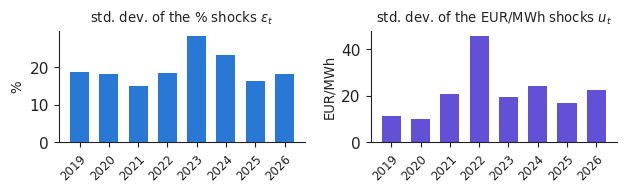

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.1))
x = np.arange(len(YEARS))
axs[0].bar(x, [sd_pct[y] for y in YEARS], color=C_PCT, width=0.65)
axs[0].set_ylabel('%', fontsize=9.5)
axs[1].bar(x, [sd_eur[y] for y in YEARS], color=C_EUR, width=0.65)
axs[1].set_ylabel('EUR/MWh', fontsize=9.5)
for ax in axs:
    ax.set_xticks(x)
    ax.set_xticklabels([str(y) for y in YEARS], fontsize=8.5, rotation=45, ha='right', rotation_mode='anchor')
axs[0].set_title(r'std. dev. of the % shocks $\varepsilon_t$', fontsize=9.5)
axs[1].set_title(r'std. dev. of the EUR/MWh shocks $u_t$', fontsize=9.5)
fig.tight_layout(rect=(0, 0.02, 1, 1))
plt.savefig('vol_units.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()